# NISAR SM inversion (Alaska)

Same De Zan coherence/phase-closure soil-moisture inversion as
[`NISAR_SM.ipynb`](NISAR_SM.ipynb) (`calc_SM_coherences`/`invert_sm` from
`INSAR4SM-main`, in-situ-driven per-station dry-date selection, no ERA5), for
Alaska, running **SoilGrids texture only, HH only, both depths**:

- **SoilGrids** (`soilgrids_data/alaska/`) -- mirroring `NISAR_SM.ipynb`'s own
  SoilGrids-anchor variant (cells 13/18). In-situ ISMN texture is no longer
  used here (dropped in favor of SoilGrids alone).
- **HH only** -- HV dropped; `POLARIZATIONS` (Section 4) controls this, so
  adding `"HV"` back to that tuple is enough to restore it.
- **5cm (main) and 20cm (secondary) depth** -- mirroring `NISAR_SM.ipynb`'s own
  two depth variants. The 20cm run reuses the *same* dry-anchor acquisition
  date as the 5cm run for a given (station, track) -- only the in-situ depth
  read for the dry-state value changes -- so the two stay a controlled
  comparison, exactly like `NISAR_SM.ipynb`'s own cells 18/24.

That's 2 variants per (station, track): (SoilGrids, 5cm), (SoilGrids, 20cm).

**Coherence and closure phase are not recomputed here.** They're read directly
from `alaska_GSLC_coherence_closure/{station}_NISAR_GSLC_coherence.csv`
(`Earsel26_NISAR-main/notebooks/nisar_data/`, written by that repo's notebook
04) -- which now carries `phase_<pol>` alongside `coherence_<pol>` for every
pair (the *full* `N(N-1)/2` matrix, not a sequential-only subset), specifically
so `coherence_<pol> * exp(i * phase_<pol>)` reconstructs the same complex
interferometric value `calc_SM_coherences`/`invert_sm` need, without touching
the raw GSLC windows a second time. (Both of those were fixed in
`nisar_coherence_closure.py` for this -- previously it only saved sequential
pairs/triplets and magnitude-only coherence, sufficient for the
`Checks_alaska.ipynb` diagnostic but not for feeding an actual inversion.
**Re-run notebook 04 first** if `alaska_GSLC_coherence_closure/` still has the
old sequential-only, magnitude-only CSVs.)

**Per (station, track), not a single stack** -- Alaska stations are typically
covered by several different NISAR relative orbits (unlike Spain's
single-track `stack_gslcs` stack), so the inversion runs independently once
per (station, track) group that has enough acquisitions.

**SoilGrids Alaska coverage is split into two longitude tiles**
(`sand_0to5cm.tif` covering lon <= -150, `sand_0to5cm_ii.tif` covering
lon >= -150 -- confirmed by inspecting both rasters' bounds, since the AOI was
too large for one download) -- `sample_soilgrids` below tries both and uses
whichever tile actually contains the station.

**`TurnagainPass` has no in-situ data at all** (its raw ISMN CSV is genuinely
empty) and is skipped everywhere ground truth is needed (dry-date selection,
the final comparison) -- SoilGrids-anchor runs are still possible for it as
long as coherence/closure data exists, just with the generic 14% dry-state
fallback.

In [1]:
import sys
import os
from pathlib import Path

import pyproj
pyproj.datadir.set_data_dir(os.path.join(sys.prefix, "Library", "share", "proj"))


def require_globals(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f"Missing {missing} -- run the earlier setup cells first "
            "(the kernel may have been restarted)."
        )


BASE = Path.cwd()
EARSEL_NOTEBOOKS = BASE / "Earsel26_NISAR-main" / "notebooks"
COH_CLOSURE_DIR = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_GSLC_coherence_closure"
INSITU_DIR = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "station_data"
SOILGRIDS_DIR = BASE / "soilgrids_data" / "alaska"

if str(BASE / "INSAR4SM-main") not in sys.path:
    sys.path.append(str(BASE / "INSAR4SM-main"))

import numpy as np
import pandas as pd
import rasterio
from insar4sm.coh_funcs import calc_SM_coherences
from insar4sm.inversion import invert_sm


C:\Users\geoka\miniconda3\envs\nisar-era5\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 1. Station list

In [2]:
require_globals("EARSEL_NOTEBOOKS")

import json

stations_path = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "stations.geojson"
with open(stations_path) as f:
    stations_geojson = json.load(f)
stations = {
    feat["properties"]["station_val"]: (
        feat["geometry"]["coordinates"][1],  # lat
        feat["geometry"]["coordinates"][0],  # lon
    )
    for feat in stations_geojson["features"]
}
print(f"Loaded {len(stations)} stations")


Loaded 20 stations


## 2. In-situ SM reader and a generic bracket-interpolator

Irregular real sensor timestamps (SNOTEL/USCRN, not a fixed hourly grid), so
`interp_insitu_at` brackets the nearest real readings and caps how far apart
they're allowed to be, rather than assuming a fixed grid -- same as
`Checks_alaska.ipynb`.

In [3]:
require_globals("INSITU_DIR")

MAX_GAP_HOURS = 6
DEPTH_MAIN = 0.05
DEPTH_SECONDARY = 0.20

def read_insitu(station, depth):
    path = INSITU_DIR / f"{station}_ts_{depth:.2f}.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    return df.iloc[:, 0].sort_index()  # single sm_<depth> column, whatever it's named


def interp_insitu_at(series, ts):
    before = series.loc[:ts]
    after = series.loc[ts:]
    if before.empty or after.empty:
        return np.nan
    t0, v0 = before.index[-1], before.iloc[-1]
    t1, v1 = after.index[0], after.iloc[0]
    if t0 == t1:
        return float(v0)
    gap_hours = (t1 - t0).total_seconds() / 3600.0
    if gap_hours > MAX_GAP_HOURS:
        return np.nan
    frac = (ts - t0).total_seconds() / (t1 - t0).total_seconds()
    return float(v0 + frac * (v1 - v0))

## 3. Soil texture: SoilGrids

**SoilGrids**: `sample_soilgrids` tries both longitude-split tiles per band and
returns the value (raw g/kg, /10 to get %) from whichever one actually contains
the station -- uses the 0-5cm layer for the 5cm-anchor variant and the 15-30cm
layer (the bracket that actually contains 20cm) for the 20cm-anchor variant,
same convention as `NISAR_SM.ipynb`.

In-situ ISMN texture is no longer used here -- SoilGrids is the only texture
source now (see Section 7).

In [4]:
require_globals("SOILGRIDS_DIR", "stations")


def sample_soilgrids(band_stem, lon, lat):
    for suffix in ("", "_ii"):
        path = SOILGRIDS_DIR / f"{band_stem}{suffix}.tif"
        if not path.exists():
            continue
        with rasterio.open(path) as src:
            row, col = src.index(lon, lat)
            if not (0 <= row < src.height and 0 <= col < src.width):
                continue
            val = float(src.read(1)[row, col])
            if 0 < val <= 1000:  # plausible g/kg range; SoilGrids has no explicit nodata sentinel here
                return val / 10.0  # g/kg -> %
    return None


def porosity_from_texture(sand_pct, clay_pct):
    return 100 * (0.332 - 7.251e-4 * sand_pct + 0.1276 * np.log10(clay_pct))


TEXTURE_LAYERS = {DEPTH_MAIN: "0to5cm", DEPTH_SECONDARY: "15to30cm"}

texture_soilgrids = {}
for station, (lat, lon) in stations.items():
    sg_by_depth = {}
    for depth, layer in TEXTURE_LAYERS.items():
        sand_sg = sample_soilgrids(f"sand_{layer}", lon, lat)
        clay_sg = sample_soilgrids(f"clay_{layer}", lon, lat)
        if sand_sg is not None and clay_sg is not None:
            sg_by_depth[depth] = {"sand_pct": sand_sg, "clay_pct": clay_sg, "porosity_pct": porosity_from_texture(sand_sg, clay_sg)}
    if sg_by_depth:
        texture_soilgrids[station] = sg_by_depth

print(f"SoilGrids texture: {len(texture_soilgrids)}/{len(stations)} station(s)")

SoilGrids texture: 19/20 station(s)


## 4. Load the precomputed coherence/closure CSVs, build per-(station, track, pol) matrices

Reads `{station}_NISAR_GSLC_coherence.csv` (full pairwise matrix, magnitude +
phase per pol) directly -- no raw pixel access. `slc_dates_group[key]` (`key =
(station, track)`) is the sorted list of that group's acquisition dates,
derived from the CSV's own `date_1`/`date_2` columns, and `inc_angle_group[key]`
the mean `local_incidence_angle_deg` across that group's rows -- both
polarization-independent (same acquisitions, same geometry). `coh_full_ds_group`/
`ph_ds_group` are keyed `(station, track, pol)` -- the reconstructed `(1, n, n)`
matrices `calc_SM_coherences`/`invert_sm` expect, built once per polarization in
`POLARIZATIONS` (this section's own first line) -- **HH only** by default now;
add `"HV"` back to that tuple to restore it.

In [5]:
require_globals("COH_CLOSURE_DIR", "stations")

POLARIZATIONS = ("HH",)
COH_THRESHOLD = 0.3  # below this, a pair is excluded from the coherence-fit term (see NISAR_SM.ipynb)

slc_dates_group = {}
inc_angle_group = {}
coh_full_ds_group = {}  # (station, track, pol) -> (1, n, n)
ph_ds_group = {}        # (station, track, pol) -> (1, n, n)

for station in stations:
    coh_path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_coherence.csv"
    if not coh_path.exists():
        continue
    df = pd.read_csv(coh_path)
    for pol in POLARIZATIONS:
        if f"phase_{pol}" not in df.columns:
            raise RuntimeError(
                f"{coh_path} has no 'phase_{pol}' column -- it was written before "
                "nisar_coherence_closure.py's process_station() was fixed to save "
                "full-pairwise-matrix coherence + phase (not just sequential-pair, "
                "magnitude-only). Re-run Earsel26_NISAR-main's notebook 04 first to "
                "regenerate alaska_GSLC_coherence_closure/ with the current code, "
                "then re-run this notebook."
            )
    df["date_1"] = pd.to_datetime(df["date_1"])
    df["date_2"] = pd.to_datetime(df["date_2"])

    for track, df_track in df.groupby("orbit_num"):
        dates = sorted(set(df_track["date_1"]) | set(df_track["date_2"]))
        n = len(dates)
        if n < 3:
            continue  # can't form a phase-closure triplet
        date_idx = {d: i for i, d in enumerate(dates)}

        slc_dates_group[(station, track)] = dates
        inc_angle_group[(station, track)] = float(df_track["local_incidence_angle_deg"].mean())

        for pol in POLARIZATIONS:
            coh_full_ds = np.full((1, n, n), np.nan, dtype=float)
            ph_ds = np.zeros((1, n, n), dtype=np.complex128)
            for i in range(n):
                ph_ds[0, i, i] = 1.0 + 0j

            for row in df_track.itertuples():
                i, j = date_idx[row.date_1], date_idx[row.date_2]
                coh_val = getattr(row, f"coherence_{pol}")
                phase_val = getattr(row, f"phase_{pol}")
                if np.isnan(coh_val) or np.isnan(phase_val):
                    continue
                ph_val = coh_val * np.exp(1j * phase_val)
                ph_ds[0, i, j] = ph_val
                ph_ds[0, j, i] = np.conj(ph_val)
                if coh_val < COH_THRESHOLD:
                    coh_full_ds[0, i, j] = np.nan
                    coh_full_ds[0, j, i] = np.nan
                else:
                    coh_full_ds[0, i, j] = coh_val
                    coh_full_ds[0, j, i] = coh_val

            coh_full_ds_group[(station, track, pol)] = coh_full_ds
            ph_ds_group[(station, track, pol)] = ph_ds

print(f"{len(slc_dates_group)} (station, track) group(s) with >= 3 acquisitions")
for key, dates in slc_dates_group.items():
    print(f"  {key[0]} track {key[1]}: {len(dates)} acquisition(s)")


83 (station, track) group(s) with >= 3 acquisitions
  MooseInc track 15: 4 acquisition(s)
  MooseInc track 78: 5 acquisition(s)
  MooseInc track 87: 5 acquisition(s)
  MooseInc track 150: 5 acquisition(s)
  AtigunPass track 63: 5 acquisition(s)
  AtigunPass track 73: 4 acquisition(s)
  AtigunPass track 102: 4 acquisition(s)
  AtigunPass track 164: 5 acquisition(s)
  Coldfoot track 63: 5 acquisition(s)
  Coldfoot track 73: 4 acquisition(s)
  Coldfoot track 145: 5 acquisition(s)
  Coldfoot track 164: 5 acquisition(s)
  EagleSummit track 15: 4 acquisition(s)
  EagleSummit track 63: 5 acquisition(s)
  EagleSummit track 87: 5 acquisition(s)
  EagleSummit track 116: 4 acquisition(s)
  EagleSummit track 135: 5 acquisition(s)
  EagleSummit track 164: 5 acquisition(s)
  GobblersKnob track 63: 5 acquisition(s)
  GobblersKnob track 73: 4 acquisition(s)
  GobblersKnob track 145: 5 acquisition(s)
  GobblersKnob track 164: 5 acquisition(s)
  GraniteCrk track 15: 4 acquisition(s)
  GraniteCrk track 6

## 5. Per-(station, track) dry-date selection (5cm-anchored)

Same in-situ-driven approach as `NISAR_SM.ipynb` (no ERA5): the acquisition
with the lowest interpolated 5cm in-situ SM reading becomes that group's dry
anchor. Used for **both variants** -- the 20cm runs reuse this same
`dry_acq_time_group`/`dry_bands_inds_group`/`SM_sorting_group`/
`SM_index_init_group`, only re-reading the in-situ value at 20cm for the
dry-state (Section 6), exactly like `NISAR_SM.ipynb`'s own cells 18/24.

In [6]:
require_globals("slc_dates_group")

dry_idx_group = {}
dry_acq_time_group = {}
dry_bands_inds_group = {}
SM_sorting_group = {}
SM_index_init_group = {}
sm_dry_state_5cm_group = {}

for key, dates in slc_dates_group.items():
    station, track = key
    n = len(dates)
    series = read_insitu(station, DEPTH_MAIN)
    vals = None
    if series is not None:
        vals = np.array([interp_insitu_at(series, ts) for ts in dates])
    if vals is None or np.all(np.isnan(vals)):
        idx = 0
        sorting = np.arange(n)
        dry_val_pct = 14.0
    else:
        idx = int(np.nanargmin(vals))
        sorting = np.argsort(vals)  # NaN entries sort last, numpy's default
        dry_val_pct = float(vals[idx] * 100)
    dry_idx_group[key] = idx
    dry_acq_time_group[key] = dates[idx].to_pydatetime()
    dry_bands_inds_group[key] = np.array([idx], dtype=int)
    SM_sorting_group[key] = sorting
    init = np.empty(n)
    init[sorting] = np.linspace(10, 30, n)
    SM_index_init_group[key] = init
    sm_dry_state_5cm_group[key] = dry_val_pct

print("Per-(station, track) dry-anchor acquisition and 5cm dry state:")
for key in slc_dates_group:
    print(f"  {key[0]} track {key[1]}: {dry_acq_time_group[key]}  {sm_dry_state_5cm_group[key]:.2f}%")


Per-(station, track) dry-anchor acquisition and 5cm dry state:
  MooseInc track 15: 2026-07-09 05:52:56  40.80%
  MooseInc track 78: 2026-07-13 14:30:44  40.80%
  MooseInc track 87: 2026-07-14 05:44:37  40.80%
  MooseInc track 150: 2026-07-06 14:22:25  40.80%
  AtigunPass track 63: 2026-07-12 13:34:50  9.20%
  AtigunPass track 73: 2026-07-13 06:23:52  8.12%
  AtigunPass track 102: 2026-07-03 06:39:55  12.67%
  AtigunPass track 164: 2026-07-07 13:43:11  10.00%
  Coldfoot track 63: 2026-08-17 13:34:48  18.10%
  Coldfoot track 73: 2026-07-13 06:23:52  19.88%
  Coldfoot track 145: 2026-08-11 06:15:48  19.00%
  Coldfoot track 164: 2026-08-24 13:43:09  18.60%
  EagleSummit track 15: 2026-08-14 05:51:07  8.97%
  EagleSummit track 63: 2026-07-12 13:34:14  14.26%
  EagleSummit track 87: 2026-07-14 05:43:01  11.40%
  EagleSummit track 116: 2026-07-04 05:59:29  14.80%
  EagleSummit track 135: 2026-08-10 13:25:53  13.24%
  EagleSummit track 164: 2026-08-12 13:42:32  11.50%
  GobblersKnob track 63:

## 6. 20cm dry state (same anchor date, different in-situ depth read)

In [7]:
require_globals("dry_acq_time_group")

sm_dry_state_20cm_group = {}
for key in slc_dates_group:
    station, track = key
    series = read_insitu(station, DEPTH_SECONDARY)
    if series is not None:
        val = interp_insitu_at(series, dry_acq_time_group[key])
        if np.isnan(val):
            val = series.min()
        sm_dry_state_20cm_group[key] = float(val * 100)
    else:
        sm_dry_state_20cm_group[key] = 14.0


## 7. Run the inversion

`run_inversion` is the shared body for both variants -- same
`calc_SM_coherences`/`invert_sm` call `NISAR_SM.ipynb` uses, parameterized by
which texture (`clay_pct`/`sand_pct`/`porosity_pct`) and which depth's
`sm_dry_state` to use.

In [8]:
require_globals(
    "coh_full_ds_group", "ph_ds_group", "slc_dates_group", "inc_angle_group",
    "SM_sorting_group", "SM_index_init_group", "dry_bands_inds_group", "dry_acq_time_group",
)


def run_inversion(key, pol, sm_dry_state, clay_pct, sand_pct, porosity_pct):
    n = len(slc_dates_group[key])
    slc_dates_arr = np.array([d.to_pydatetime() for d in slc_dates_group[key]], dtype=object)

    coh_sm, _, _ = calc_SM_coherences(
        Datetimes=slc_dates_arr,
        SM_sorting=SM_sorting_group[key],
        n_bands=n,
        n_ds=1,
        ind_DS=0,
        coh_full_DS=coh_full_ds_group[(key[0], key[1], pol)],
        band_start=0,
        band_end=n,
        n_dry_bands=1,
        max_coh_flag=True,
        simple_exp_model=False,
        sm_only_mode=True,
    )

    sm_pix = invert_sm(
        ph_DS=ph_ds_group[(key[0], key[1], pol)],
        coh_sm=coh_sm[0],
        SM_index=SM_index_init_group[key],
        dry_bands_inds=dry_bands_inds_group[key],
        slc_dates=slc_dates_arr,
        DS_ind=0,
        driest_date=dry_acq_time_group[key],
        inc_DS=np.array([inc_angle_group[key]]),
        band_start=0,
        band_end=n,
        nbands=n,
        opt_method="SLSQP",
        opt_parms={"ftol": 1e-3, "eps": 0.01, "maxiter": 50},
        ph_closure_dist=5,
        weight_factor=1.0,
        sm_dry_state=sm_dry_state,
        freq_GHz=1.2575,
        clay_pct=clay_pct,
        sand_pct=sand_pct,
    )
    return np.clip(sm_pix, 0, porosity_pct)


sm_map = {}  # (station, track, texture_source, depth_label, pol) -> sm array
for key in slc_dates_group:
    station, track = key

    for pol in POLARIZATIONS:
        if station in texture_soilgrids:
            for depth, dry_state_group, depth_label in (
                (DEPTH_MAIN, sm_dry_state_5cm_group, "5cm"),
                (DEPTH_SECONDARY, sm_dry_state_20cm_group, "20cm"),
            ):
                tex = texture_soilgrids[station].get(depth)
                if tex is None:
                    continue
                sm_pix = run_inversion(key, pol, dry_state_group[key], tex["clay_pct"], tex["sand_pct"], tex["porosity_pct"])
                sm_map[(station, track, "soilgrids", depth_label, pol)] = sm_pix
                print(f"  {station} track {track} [soilgrids, {depth_label}, {pol}]: SM = {sm_pix.round(2)} %")

print(f"\nInversion complete: {len(sm_map)} (station, track, texture, depth, pol) result(s)")

  AtigunPass track 63 [soilgrids, 5cm, HH]: SM = [34.82 29.97  9.2  42.71 12.15] %


  AtigunPass track 63 [soilgrids, 20cm, HH]: SM = [35.51 30.86 10.46 41.87 13.52] %
  AtigunPass track 73 [soilgrids, 5cm, HH]: SM = [14.45 26.51  8.12 24.91] %


  AtigunPass track 73 [soilgrids, 20cm, HH]: SM = [18.12 31.95 10.5  30.3 ] %
  AtigunPass track 102 [soilgrids, 5cm, HH]: SM = [12.67 10.13 26.63 24.77] %
  AtigunPass track 102 [soilgrids, 20cm, HH]: SM = [19.2  15.32 27.43 24.56] %


  AtigunPass track 164 [soilgrids, 5cm, HH]: SM = [17.84 10.   14.21 22.65 24.69] %


  AtigunPass track 164 [soilgrids, 20cm, HH]: SM = [22.93 14.04 18.85 27.97 30.21] %


...

  UpperNomeCreek track 164 [soilgrids, 20cm, HH]: SM = [40.17 18.91 26.22 21.3  33.15] %
  Kenai-29-ENE track 15 [soilgrids, 5cm, HH]: SM = [13.09 26.47 19.56  4.86] %
  Kenai-29-ENE track 15 [soilgrids, 20cm, HH]: SM = [26.2  11.81 33.86 15.45] %


  Kenai-29-ENE track 49 [soilgrids, 5cm, HH]: SM = [14.1  42.55 29.43 42.55] %
  Kenai-29-ENE track 49 [soilgrids, 20cm, HH]: SM = [24.58  9.94  0.    9.55] %


  Kenai-29-ENE track 87 [soilgrids, 5cm, HH]: SM = [11.94 12.37 22.01 25.16 18.84] %
  Kenai-29-ENE track 87 [soilgrids, 20cm, HH]: SM = [14.58 25.1  24.42 29.49 21.12] %


  Kenai-29-ENE track 150 [soilgrids, 5cm, HH]: SM = [10.03 13.1  42.55 27.16 18.17] %


  Kenai-29-ENE track 150 [soilgrids, 20cm, HH]: SM = [ 5.58 24.7  38.25 17.44 38.76] %

Inversion complete: 158 (station, track, texture, depth, pol) result(s)


## 8. Compare against in-situ SM

Per (station, track, texture_source, depth): the estimated SM at each
acquisition vs. the interpolated in-situ reading at that same timestamp and
depth, excluding the dry-anchor band (tautologically forced to match by the
inversion's own equality constraint) -- same exclusion `NISAR_SM.ipynb` and
`Checks_alaska.ipynb` both apply.

In [9]:
require_globals("sm_map", "slc_dates_group", "dry_idx_group")

DEPTH_BY_LABEL = {"5cm": DEPTH_MAIN, "20cm": DEPTH_SECONDARY}

results = []
results_raw = {}  # (station, track, texture_source, depth_label, pol) -> (real_valid, est_valid)
for (station, track, texture_source, depth_label, pol), sm_pix in sm_map.items():
    key = (station, track)
    dates = slc_dates_group[key]
    series = read_insitu(station, DEPTH_BY_LABEL[depth_label])
    if series is None:
        continue
    real_pct = np.array([interp_insitu_at(series, ts) for ts in dates]) * 100

    valid = ~np.isnan(real_pct) & ~np.isnan(sm_pix) & (np.arange(len(sm_pix)) != dry_idx_group[key])
    if not np.any(valid):
        continue
    est_valid = sm_pix[valid]
    real_valid = real_pct[valid]
    rmse = np.sqrt(np.mean((est_valid - real_valid) ** 2))
    bias = np.mean(est_valid - real_valid)
    r = (np.corrcoef(est_valid, real_valid)[0, 1]
         if len(est_valid) > 1 and np.std(est_valid) > 0 and np.std(real_valid) > 0 else np.nan)
    results.append({
        "station": station, "track": track, "texture_source": texture_source, "depth": depth_label,
        "pol": pol, "n": len(est_valid), "rmse": rmse, "bias": bias, "r": r,
    })
    results_raw[(station, track, texture_source, depth_label, pol)] = (real_valid, est_valid)

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


          station  track texture_source depth pol  n      rmse       bias         r
       AtigunPass     63      soilgrids   5cm  HH  2 10.854097   7.418673  1.000000
       AtigunPass     63      soilgrids  20cm  HH  2  7.303015   0.217131  1.000000
       AtigunPass     73      soilgrids   5cm  HH  2 10.000339   9.916874 -1.000000
       AtigunPass     73      soilgrids  20cm  HH  2  7.557832   7.484638 -1.000000
       AtigunPass    102      soilgrids   5cm  HH  2  7.843796   3.150663  1.000000
       AtigunPass    102      soilgrids  20cm  HH  2  5.138859  -3.028361  1.000000
       AtigunPass    164      soilgrids   5cm  HH  4  7.077487   6.166504  0.817914
       AtigunPass    164      soilgrids  20cm  HH  4  4.261507   2.836789  0.975029
         Coldfoot     63      soilgrids   5cm  HH  3 15.315073 -13.271327 -0.089108
         Coldfoot     63      soilgrids  20cm  HH  4  9.354975  -6.702556  0.146278
         Coldfoot     73      soilgrids   5cm  HH  3  8.102724  -1.663460  0

## 8b. SME2 comparison (reference product)

[`SME2_alaska.ipynb`](SME2_alaska.ipynb) downloaded NISAR L3 SME2 (~200m
EASE-Grid 2.0 soil moisture) for every station's NISAR acquisition window;
this section samples the nearest pixel to each station (`SME2_data_alaska/`
+ its `station_manifest.json`) and compares it against 5cm in-situ SM,
alongside the coherence-based estimates above -- SME2 is an independent
reference product, not something this project's inversion controls.

**Quality-flag correction**: `retrievalQualityFlag`'s own field description
(read directly off the HDF5 attrs) says it's a **bitmask**, not the
0=clean/non-zero=anomaly enum `SME2_footprint_check.ipynb` assumed for Spain
-- bit 0 (value 1) is the actual recommended/not-recommended flag (`0` =
recommended), while bits 1-3 just record which of the PMI/TSR/DSG algorithms
contributed to that pixel. Every Alaska pixel checked has at least one
algorithm bit set, so the old `rqf == 0` gate matched **zero** of 505
station-pixel-date samples across every downloaded file -- the correct gate
is `(rqf & 1) == 0`, which recovers 202/505 (40%). Even with the fix, only 7
of 17 stations (EagleSummit, GobblersKnob, GraniteCrk, ImnaviatCreek,
PilgrimHotSprings, RockyPoint, UpperNomeCreek) have *any* recommended
retrieval at their pixel across the whole campaign -- the rest are flagged
not-recommended on every single date. That's a real, geographically-patterned
product limitation (likely dense boreal-forest/terrain effects the retrieval
algorithm flags consistently there), not a bug in this sampling code.

Compared at **5cm only** -- SME2 targets near-surface soil moisture, so a
20cm comparison wouldn't be physically meaningful.

In [10]:
require_globals("stations", "results_df")

import json as _json
import h5py
from pyproj import Transformer

SME2_DIR = BASE / "SME2_data_alaska"
SME2_FILL = -9999

_manifest_path = SME2_DIR / "station_manifest.json"
if _manifest_path.exists():
    with open(_manifest_path) as f:
        sme2_manifest = _json.load(f)
else:
    sme2_manifest = {}


def read_sme2_series(station):
    """Nearest-pixel SME2 soil moisture (%) per acquisition, filtered to
    'recommended' retrievals only (retrievalQualityFlag bit 0 == 0 -- see
    the markdown above for why this isn't just `rqf == 0`)."""
    files = sme2_manifest.get(station, [])
    if not files or station not in stations:
        return pd.Series(dtype=float)
    lat, lon = stations[station]
    records = {}
    for fn in files:
        fp = SME2_DIR / fn
        if not fp.exists():
            continue
        with h5py.File(fp, "r") as h:
            g = h["science/LSAR/SME2/grids"]
            proj = int(g["projection"][()])
            xc = g["xCoordinates"][:]
            yc = g["yCoordinates"][:]
            transformer = Transformer.from_crs("EPSG:4326", f"EPSG:{proj}", always_xy=True)
            px, py = transformer.transform(lon, lat)
            ix = int(np.argmin(np.abs(xc - px)))
            iy = int(np.argmin(np.abs(yc - py)))
            sm_val = float(g["soilMoisture"][iy, ix])
            rqf_val = int(g["retrievalQualityFlag"][iy, ix])
            if sm_val == SME2_FILL or rqf_val == SME2_FILL or (rqf_val & 1) != 0 or sm_val < 0:
                continue
            ts = h["science/LSAR/identification/zeroDopplerStartTime"][()]
            if isinstance(ts, bytes):
                ts = ts.decode()
            records[pd.Timestamp(ts)] = sm_val * 100  # fraction -> %

    return pd.Series(records, dtype=float).sort_index()


SME2_CACHE_PATH = SME2_DIR / "sme2_cache.csv"
if SME2_CACHE_PATH.exists():
    # Prefer the small precomputed cache (station, timestamp, sm_pct -- already
    # filtered to "recommended" retrievals, exactly what read_sme2_series returns)
    # over the raw ~26 GB of HDF5 granules, which most colleagues won't have.
    _sme2_cache = pd.read_csv(SME2_CACHE_PATH, parse_dates=["timestamp"])
    sme2_series_by_station = {
        station: _sme2_cache.loc[_sme2_cache["station"] == station].set_index("timestamp")["sm_pct"].sort_index()
        for station in stations
    }
else:
    sme2_series_by_station = {station: read_sme2_series(station) for station in stations}

sme2_results = []
sme2_results_raw = {}  # station -> (real_valid, est_valid)
for station, series in sme2_series_by_station.items():
    if series.empty:
        continue
    insitu_series = read_insitu(station, DEPTH_MAIN)
    if insitu_series is None:
        continue
    real_frac = np.array([interp_insitu_at(insitu_series, ts) for ts in series.index])
    est_pct = series.values
    valid = ~np.isnan(real_frac) & ~np.isnan(est_pct)
    if not np.any(valid):
        continue
    real_valid = real_frac[valid] * 100
    est_valid = est_pct[valid]
    rmse = np.sqrt(np.mean((est_valid - real_valid) ** 2))
    bias = np.mean(est_valid - real_valid)
    r = (np.corrcoef(est_valid, real_valid)[0, 1]
         if len(est_valid) > 1 and np.std(est_valid) > 0 and np.std(real_valid) > 0 else np.nan)
    sme2_results.append({"station": station, "n": len(est_valid), "rmse": rmse, "bias": bias, "r": r})
    sme2_results_raw[station] = (real_valid, est_valid)

sme2_results_df = pd.DataFrame(sme2_results)
n_with_data = sum(1 for s in sme2_series_by_station.values() if not s.empty)
print(f"SME2: {n_with_data}/{len(stations)} station(s) with >=1 recommended retrieval; "
      f"{len(sme2_results_df)} station(s) with 5cm in-situ ground truth to compare against")
print(sme2_results_df.to_string(index=False))


SME2: 7/20 station(s) with >=1 recommended retrieval; 7 station(s) with 5cm in-situ ground truth to compare against
          station  n      rmse       bias         r
      EagleSummit 36  9.061658   1.199871 -0.114815
     GobblersKnob 13  9.704698   8.026898  0.166746
       GraniteCrk 32 10.319412   8.238714  0.441917
    ImnaviatCreek 14 23.721013 -20.540379 -0.201053
PilgrimHotSprings 24 14.105307  -7.559784 -0.845311
       RockyPoint 10 13.843887 -12.121256 -0.801562
   UpperNomeCreek 33 10.988865  -6.257665 -0.068561


## 9. Grouped summary (mean RMSE/bias/R by depth, texture source, polarization)

`results_df` has one row per (station, track, texture_source, depth, pol).
Grouping by `depth`/`texture_source`/`pol` -- same kind of aggregation
`Checks_alaska.ipynb`'s own Section 8 "Overall comparison" does for its
coherence-vs-SM-diff correlations -- shows which combination performs best on
average, independent of any single station's quirks.

In [11]:
require_globals("results_df", "sme2_results_df")

GROUP_COLS = ["depth", "texture_source", "pol"]

summary_df = (
    results_df.groupby(GROUP_COLS)
    .agg(
        n_groups=("rmse", "size"),
        n_obs=("n", "sum"),
        mean_rmse=("rmse", "mean"),
        median_rmse=("rmse", "median"),
        mean_bias=("bias", "mean"),
        mean_r=("r", "mean"),
        median_r=("r", "median"),
    )
    .reset_index()
    .sort_values(GROUP_COLS)
)
print(summary_df.to_string(index=False))

# SME2 has no track/texture/pol dimensions (one shared reference product per
# station), so it doesn't fit GROUP_COLS -- reported as its own addendum
# instead of a fake row in summary_df.
if len(sme2_results_df):
    sme2_summary_df = pd.DataFrame([{
        "depth": "5cm", "product": "SME2",
        "n_stations": len(sme2_results_df), "n_obs": int(sme2_results_df["n"].sum()),
        "mean_rmse": sme2_results_df["rmse"].mean(), "median_rmse": sme2_results_df["rmse"].median(),
        "mean_bias": sme2_results_df["bias"].mean(),
        "mean_r": sme2_results_df["r"].mean(), "median_r": sme2_results_df["r"].median(),
    }])
    print("\nSME2 (reference product; 5cm only, no track/texture/pol dimensions):")
    print(sme2_summary_df.to_string(index=False))
else:
    print("\nSME2: no station has both a recommended retrieval and 5cm in-situ ground truth.")


depth texture_source pol  n_groups  n_obs  mean_rmse  median_rmse  mean_bias   mean_r  median_r
 20cm      soilgrids  HH        70    233  12.768422    12.401657  -3.471856 0.375358  0.603629
  5cm      soilgrids  HH        74    246  11.264368    10.119189  -0.932330 0.493920  0.680195

SME2 (reference product; 5cm only, no track/texture/pol dimensions):
depth product  n_stations  n_obs  mean_rmse  median_rmse  mean_bias    mean_r  median_r
  5cm    SME2           7    162  13.106406    10.988865    -4.1448 -0.203234 -0.114815


## 10. Visualization

Two views: (1) `summary_df`'s mean RMSE as a grouped bar chart (bars grouped by
depth/texture_source, colored by polarization), and (2) a per-combination
scatter of estimated vs. in-situ SM (`results_raw`, the same valid points
`rmse`/`bias`/`r` in Section 8 were computed from) against the 1:1 line,
faceted by depth (rows) x texture source (columns) and colored by
polarization.

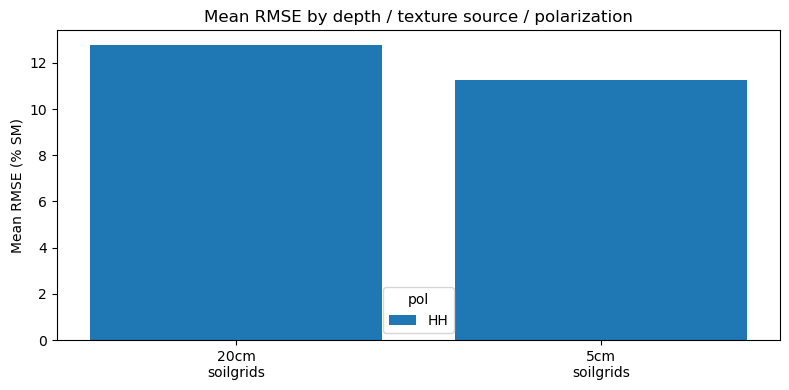

In [12]:
require_globals("summary_df")

import matplotlib.pyplot as plt

combo_labels = sorted(set(zip(summary_df["depth"], summary_df["texture_source"])))
pols_present = sorted(summary_df["pol"].unique())
x = np.arange(len(combo_labels))
width = 0.8 / len(pols_present)

fig, ax = plt.subplots(figsize=(8, 4))
for i, pol in enumerate(pols_present):
    heights = []
    for depth, texture_source in combo_labels:
        row = summary_df[
            (summary_df["depth"] == depth)
            & (summary_df["texture_source"] == texture_source)
            & (summary_df["pol"] == pol)
        ]
        heights.append(row["mean_rmse"].iloc[0] if len(row) else np.nan)
    ax.bar(x + i * width, heights, width, label=pol)

ax.set_xticks(x + width * (len(pols_present) - 1) / 2)
ax.set_xticklabels([f"{depth}\n{texture_source}" for depth, texture_source in combo_labels])
ax.set_ylabel("Mean RMSE (% SM)")
ax.set_title("Mean RMSE by depth / texture source / polarization")
ax.legend(title="pol")
fig.tight_layout()
plt.show()


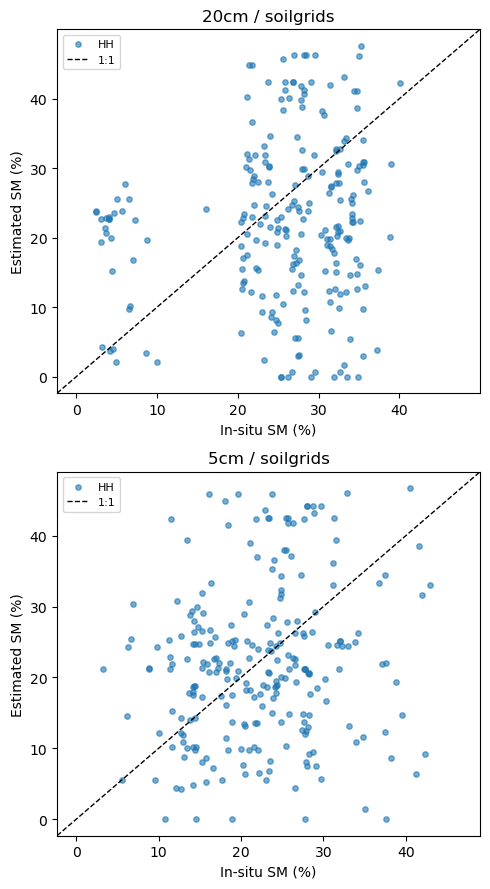

In [13]:
require_globals("results_raw", "results_df")

POL_COLORS = {"HH": "tab:blue", "HV": "tab:orange"}

depths = sorted(results_df["depth"].unique())
textures = sorted(results_df["texture_source"].unique())

fig, axes = plt.subplots(
    len(depths), len(textures), squeeze=False,
    figsize=(5 * len(textures), 4.5 * len(depths)),
)
for i, depth in enumerate(depths):
    for j, texture_source in enumerate(textures):
        ax = axes[i][j]
        for (station, track, tex, dep, pol), (real_valid, est_valid) in results_raw.items():
            if tex != texture_source or dep != depth:
                continue
            ax.scatter(real_valid, est_valid, s=15, alpha=0.6, color=POL_COLORS.get(pol, "gray"), label=pol)

        lo, hi = ax.get_xlim()
        lo2, hi2 = ax.get_ylim()
        lims = [min(lo, lo2), max(hi, hi2)]
        ax.plot(lims, lims, "k--", linewidth=1, label="1:1")
        ax.set_xlim(lims)
        ax.set_ylim(lims)
        ax.set_title(f"{depth} / {texture_source}")
        ax.set_xlabel("In-situ SM (%)")
        ax.set_ylabel("Estimated SM (%)")

        handles, labels = ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        ax.legend(by_label.values(), by_label.keys(), fontsize=8)

fig.tight_layout()
plt.show()


## 11. Per-station timeseries

For a given (depth, texture_source, pol) combination: one subplot per
station, plotting the in-situ SM series over its full recorded date range
(not clipped to that station's acquisition span, unlike an earlier version of
this notebook) against **one line per track** of estimated SM.
`plot_station_timeseries` is parameterized so any of the 2 (depth,
texture_source, pol) combinations can be plotted -- called once below with a
representative default.

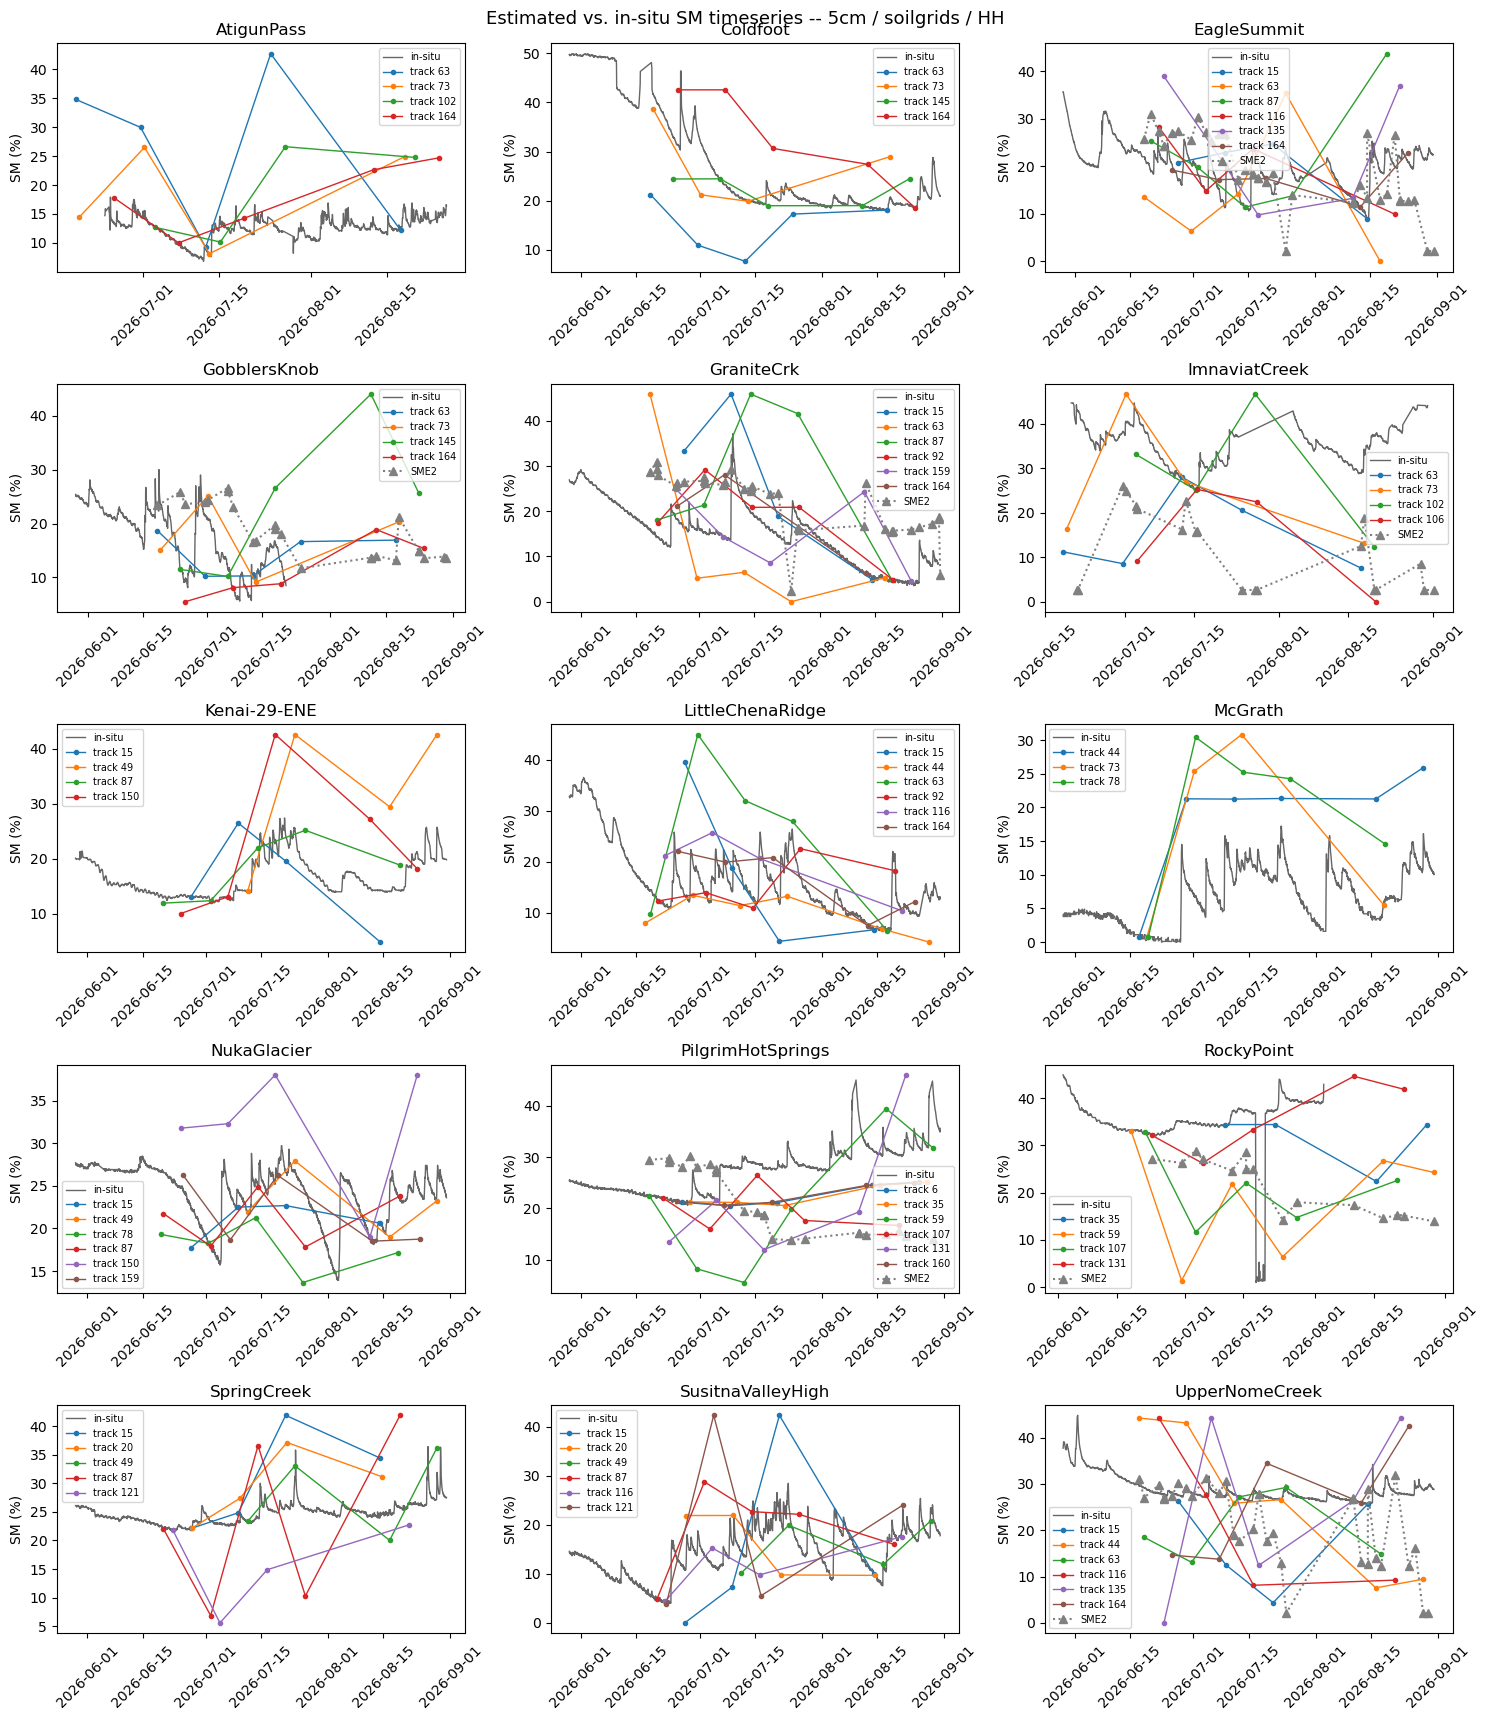

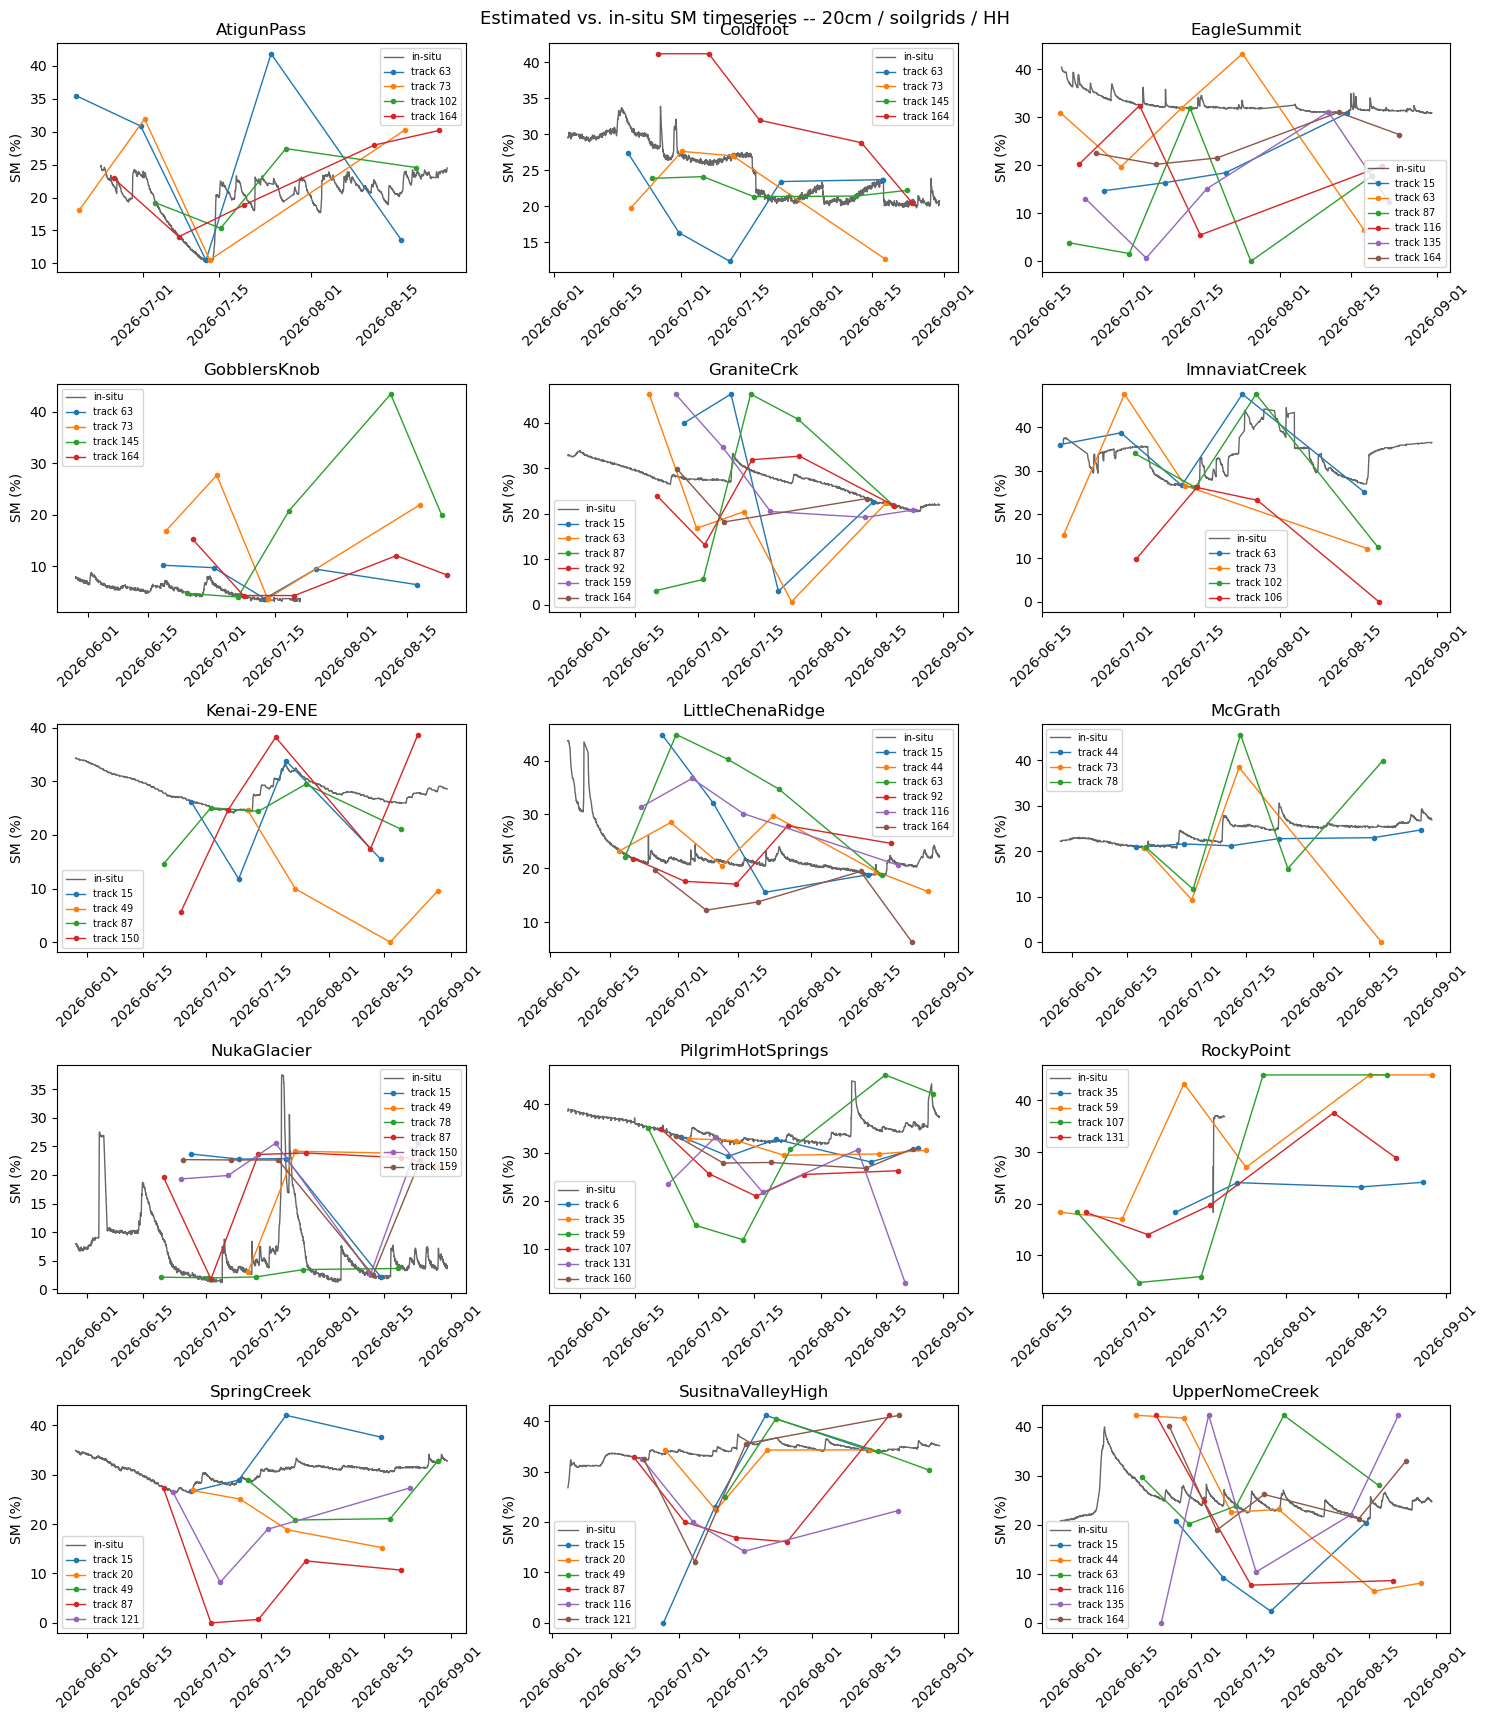

In [14]:
require_globals("sm_map", "slc_dates_group", "stations", "sme2_series_by_station")


def plot_station_timeseries(depth_label, texture_source, pol):
    depth = DEPTH_BY_LABEL[depth_label]
    keys = [k for k in sm_map if k[2] == texture_source and k[3] == depth_label and k[4] == pol]
    # Skip stations with no in-situ ground truth at all (e.g. TurnagainPass) --
    # nothing to compare against, just clutters the grid with an empty line.
    station_list = sorted({k[0] for k in keys if read_insitu(k[0], depth) is not None})
    if not station_list:
        print(f"No results with in-situ ground truth for ({depth_label}, {texture_source}, {pol})")
        return

    ncols = 3
    nrows = -(-len(station_list) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 3.5), squeeze=False)
    axes = axes.flatten()

    for idx, station in enumerate(station_list):
        ax = axes[idx]
        station_tracks = sorted(k[1] for k in keys if k[0] == station)

        series = read_insitu(station, depth)
        if series is not None:
            ax.plot(series.index, series.values * 100, color="black", linewidth=1, alpha=0.6, label="in-situ")

        for track in station_tracks:
            key = (station, track, texture_source, depth_label, pol)
            dates = slc_dates_group[(station, track)]
            sm_pix = sm_map[key]
            ax.plot(dates, sm_pix, marker="o", markersize=3, linewidth=1, label=f"track {track}")

        # SME2 is a single station-level reference series (no track/texture/pol
        # dimensions) and only targets near-surface moisture, so only overlay
        # it on the 5cm panels.
        if depth_label == "5cm":
            sme2_series = sme2_series_by_station.get(station)
            if sme2_series is not None and not sme2_series.empty:
                ax.plot(sme2_series.index, sme2_series.values, "^:", color="gray", markersize=6, label="SME2")

        ax.set_title(station)
        ax.set_ylabel("SM (%)")
        ax.legend(fontsize=7)
        ax.tick_params(axis="x", rotation=45)

    for idx in range(len(station_list), len(axes)):
        axes[idx].axis("off")

    fig.suptitle(f"Estimated vs. in-situ SM timeseries -- {depth_label} / {texture_source} / {pol}", fontsize=13)
    fig.tight_layout()
    plt.show()


plot_station_timeseries("5cm", "soilgrids", "HH")
plot_station_timeseries("20cm", "soilgrids", "HH")

<hr>

## Summary

`sm_map` holds the per-(station, track, texture_source, depth, pol) SM
estimate array (`pol` in `POLARIZATIONS` -- HH only by default now);
`results_df` (Section 8) has the RMSE/bias/R against in-situ SM for every
combination, and `results_raw` the underlying valid (real, estimated) point
pairs each of those metrics was computed from. Section 8b adds NISAR SME2
(`SME2_alaska.ipynb`'s download) as an independent 5cm-only reference product
-- `sme2_series_by_station` holds each station's nearest-pixel timeseries
(filtered to `retrievalQualityFlag`'s bit-0 "recommended" flag, corrected from
the 0=clean enum `SME2_footprint_check.ipynb` assumed for Spain -- see that
section's markdown), and `sme2_results_df` its own RMSE/bias/R, computed the
same way but with no track/texture/pol dimensions. `summary_df` (Section 9)
aggregates `results_df` by depth/texture_source/pol and prints SME2's own
aggregate stats alongside it; Section 10 plots that as a grouped RMSE bar
chart and the raw points as a faceted estimated-vs-in-situ scatter; Section
11 plots per-station SM timeseries (one line per track, plus in-situ, plus a
gray SME2 marker line on the 5cm panels). Re-run after
`alaska_GSLC_coherence_closure/` is regenerated (more acquisitions),
`01_prepare_ismn_data.ipynb`/SoilGrids data changes, or `SME2_alaska.ipynb`
downloads more granules -- everything here is purely local, no network cost.

<hr>

## 12. Export SM estimates

Writes `sm_map` out to a small CSV (station, track, texture_source, depth,
pol, date, sm_pct, is_dry_anchor) -- nothing downstream in this notebook
reads it back, this is purely so other notebooks (e.g. a per-station
exploratory-analysis one) can get at these estimates without re-running the
inversion themselves. `is_dry_anchor` flags the one acquisition per
(station, track) that was forced to match the in-situ dry state by the
inversion's own equality constraint (same exclusion Section 8's RMSE/bias/R
already applies).

In [15]:
require_globals("sm_map", "slc_dates_group", "dry_idx_group")

export_rows = []
for (station, track, texture_source, depth_label, pol), sm_pix in sm_map.items():
    dates = slc_dates_group[(station, track)]
    dry_idx = dry_idx_group[(station, track)]
    for i, (date, sm_pct) in enumerate(zip(dates, sm_pix)):
        export_rows.append({
            "station": station, "track": track, "texture_source": texture_source,
            "depth": depth_label, "pol": pol, "date": date, "sm_pct": sm_pct,
            "is_dry_anchor": i == dry_idx,
        })

sm_estimates_df = pd.DataFrame(export_rows).sort_values(["station", "track", "depth", "date"])
sm_estimates_path = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_NISAR_SM_estimates.csv"
sm_estimates_df.to_csv(sm_estimates_path, index=False)
print(f"Wrote {len(sm_estimates_df)} row(s) to {sm_estimates_path}")

Wrote 732 row(s) to D:\Docs\RS_2023\NISAR4SM\Earsel26_NISAR-main\notebooks\nisar_data\alaska_NISAR_SM_estimates.csv
